# 03 · SPCA — supervised PCA for risk premia of weak factors

**Purpose** (Giglio, Xiu & Zhang, *JF*). Estimate the risk premium of an
observable factor $g_t$ when test assets load on it only weakly, with valid
standard errors, the factor's alpha, a hedging (mimicking) portfolio, SDF weights
and a test of whether $g_t$ is spanned at all.

**Algorithm.** For $k=1,\dots,p$: (1) *screen* the $N_0$ assets most correlated
with the residual factor, (2) take the leading principal component of the
selected residual returns, (3) *deflate* returns, mean returns and the factor by
that component. Then $\hat\gamma_g=\hat\eta\hat\gamma$ and
$\hat\alpha=\bar g-\hat\eta\hat\gamma$, with Newey-West asymptotic variances.

| Parameter | Default | Options |
|---|---|---|
| `n_factors` | 1 | number of SPCA steps $p$ |
| `n_select` | 0.5 | $N_0$ (int) or share $q$ of assets (float) |
| `screening` | `"correlation"` | or `"covariance"` (paper eq. 9) |
| `zero_beta` | `False` | cross-sectionally demean returns |
| `lags` / `lag_rule` | `None` / `"newey-west"` | HAC lag or rule |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
R, G = sim.returns, sim.observable  # G = [noisy proxy of factor 1, useless factor]
names = ["proxy", "useless"]

## 1. Tuning the screening size

Giglio-Xiu-Zhang choose $N_0$ by repeated random 3-fold cross-validation of the
out-of-fold **hedging $R^2$** (how well the mimicking portfolio tracks $g_t$).

selected n_select = 100


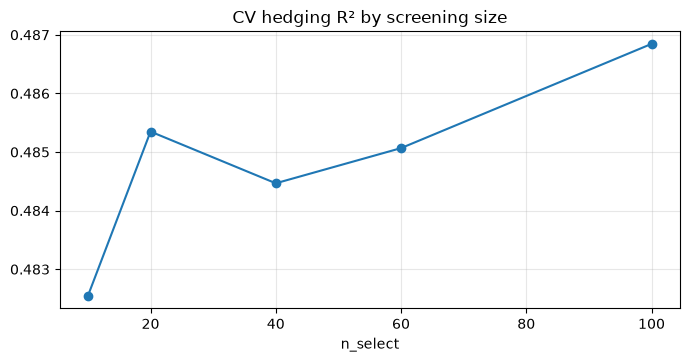

In [3]:
cv = lfm.KFold(3, shuffle=True, n_repeats=10, seed=0)
gs = lfm.GridSearchCV(
    lfm.SPCA(3), {"n_select": [10, 20, 40, 60, 100]}, cv=cv, scoring="hedging_r2"
).fit(R, factors=G)
scores = pd.DataFrame(gs.result_.to_records()).set_index("n_select")
scores["mean_score"].plot(marker="o", title="CV hedging R² by screening size")
print("selected n_select =", gs.best_params_["n_select"])

## 2. Risk premia, alphas and weak-factor tests

In [4]:
model = gs.best_model_
rp = model.risk_premia()
print(rp.summary(names))

factor           gamma_g          se        t        p    R2_g   Wald p
proxy            0.04229     0.15791     0.27    0.789   0.984    0.000
useless         -0.02459     0.05011    -0.49    0.624   0.001    0.906


In [5]:
pd.DataFrame(
    {
        "gamma_g": rp.gamma_g,
        "s.e.": rp.se,
        "alpha": rp.extra["alpha"],
        "alpha s.e.": rp.extra["alpha_se"],
        "hedging R² (in-sample)": model.hedging_r2_,
        "Wald stat": rp.wald_stat,
        "Wald p": rp.wald_pvalue,
    },
    index=names,
)

,gamma_g,s.e.,alpha,alpha s.e.,hedging R² (in-sample),Wald stat,Wald p
proxy,0.0423,0.1579,-0.0124,0.0216,0.9839,35829.8644,0.0000
useless,-0.0246,0.0501,0.3419,0.1589,0.0009,0.5590,0.9057


**Reading the output.** The proxy is spanned by the latent factors (Wald
p-value ≈ 0), so its risk premium is identified. The useless factor is not
(large Wald p-value): its premium estimate should not be interpreted.

**Population vs. sample premium.** Any estimator can only recover the premium
*realised in the sample*. In this particular sample the true factor happened to
have a low average return, far below its population mean of 0.48; SPCA tracks
the realised value closely. The standard errors (≈ 0.16 for $T=600$) reflect
exactly this sampling uncertainty — notebook 09 shows by Monte Carlo that the
95 % intervals cover the population premium in about 95 % of samples.

In [6]:
pd.Series(
    {
        "population premium of factor 1": float(sim.risk_premia[0]),
        "sample mean of the true factor 1": float(sim.factors[:, 0].mean()),
        "SPCA estimate for the proxy": float(rp.gamma_g[0]),
        "standard error": float(rp.se[0]),
    }
).round(4)

population premium of factor 1      0.4800
sample mean of the true factor 1    0.0409
SPCA estimate for the proxy         0.0423
standard error                      0.1579
dtype: float64

## 3. Nested models and outputs

`risk_premia(p)` uses the first $p$ SPCA steps without refitting.

In [7]:
pd.DataFrame(
    {p: model.risk_premia(p).gamma_g for p in range(1, model.n_factors + 1)}, index=names
).rename(columns=lambda p: f"p={p}")

,p=1,p=2,p=3
proxy,0.0398,0.0498,0.0423
useless,0.0004,0.0060,-0.0246


In [8]:
print("assets selected per step:", [len(s) for s in model.selected_])
print(
    "latent factors V (T x p):",
    model.latent_factors_.shape,
    "| V'V/T = I:",
    np.allclose(model.latent_factors_.T @ model.latent_factors_ / 600, np.eye(model.n_factors)),
)
print(
    "mimicking weights (d x N):",
    model.mimicking_weights_.shape,
    "| SDF weights (N,):",
    model.sdf_weights_.shape,
)

assets selected per step: [100, 100, 100]
latent factors V (T x p): (600, 3) | V'V/T = I: True
mimicking weights (d x N): (2, 100) | SDF weights (N,): (100,)


## 4. Out-of-sample hedging

Fit on the first half, evaluate the hedging portfolios on the second half.

In [9]:
half = lfm.SPCA(3, n_select=gs.best_params_["n_select"]).fit(R[:300], factors=G[:300])
pd.Series(half.hedging_r2(R[300:], G[300:]), index=names, name="out-of-sample hedging R²")

proxy      0.9824
useless   -0.0052
Name: out-of-sample hedging R², dtype: float64

**Validation.** Identical to the authors' `SPCA_cv.m`. Note: their code keeps
$N_0+1$ assets per step (1-based indexing); the package keeps exactly $N_0$ as in
the paper, so `n_select=N0 + 1` reproduces their output (`docs/validation.md`).